# 变分积分器求解自由落体运动

- [周详](xiangzhou@whu.edu.cn)
- 武汉大学
- 2026年9月28日

到此为止的所有方法——欧拉法、RK2、RK45——都在离散**运动方程**。本例换一条路：离散**变分原理**本身。不再对 $\dot x = v,\ \dot v = g$ 逐点逼近，而是把哈密顿原理"使作用量取极值"原封不动搬到离散时间上，让数值轨道成为**离散作用量的驻值序列**——这样得到的格式称为**变分积分器**（variational integrator）。

自由落体（$x$ 轴向下为正，取 $x = 0$ 处势能为零），拉格朗日量与作用量：

$$
L(x, \dot x) = \tfrac{1}{2}m\dot x^2 + mgx,
\qquad
S[x] = \int_{0}^{T} L\, dt
$$

**第一步：离散化拉格朗日量。** 用"区间平均速度 + 区间中点位置"近似每个子区间上的 $L$，定义**离散拉格朗日量**（步长 $h$）：

$$
L_d(x_k, x_{k+1}) = h\left[\tfrac{1}{2}m\left(\frac{x_{k+1}-x_k}{h}\right)^2 + mg\,\frac{x_k+x_{k+1}}{2}\right]
$$

**第二步：离散变分原理。** 对离散作用量 $S_d = \sum_k L_d(x_k, x_{k+1})$ 关于中间节点变分并令其为零，得**离散欧拉–拉格朗日方程**（DEL）：

$$
\frac{\partial L_d}{\partial x_k}(x_{k-1}, x_k) + \frac{\partial L_d}{\partial x_k}(x_k, x_{k+1}) = 0
\;\;\Longrightarrow\;\;
x_{k+1} - 2x_k + x_{k-1} = g h^2
$$

**第三步：离散动量定起点。** 位置序列有两组解，还需要初始条件。对**离散 Legendre 变换**定义的节点动量

$$
p_k = -\frac{\partial L_d}{\partial x_k}(x_k, x_{k+1}) = m\,\frac{x_{k+1}-x_k}{h} - \tfrac{1}{2}m g h
$$

令 $p_0 = m v_0$，反解出**启动步** $x_1 = x_0 + h v_0 + \tfrac{1}{2}g h^2$，随后只靠 DEL 递推。这一格式正是大名鼎鼎的 **Störmer–Verlet / 蛙跳法**——1907 年就被用来算分子运动，比"变分积分器"这个名字早了九十年。

**总机械能**仍取 $E = \tfrac{1}{2}mv^2 - mgx$（与第二章例 3 一致，初始时 $E_0 = 0$）。

**运行之前，先把你的预测写下来**：

1. 自由落体的解析解是 $t$ 的**二次多项式**——它的二阶差分 $x_{k+1}-2x_k+x_{k-1}$ 等于多少？DEL 会被解析解精确满足吗？位置、动量会精确到什么程度？
2. 节点动量公式里多出的 $-\tfrac{1}{2}mgh$ 是什么？区间平均速度对应哪个**时刻**的真实速度？这一项把它折算回了哪里？
3. 一个刁钻的问题：第二章例 3 中前向欧拉法的**位置序列**，会不会也满足 DEL 差分方程？如果会，欧拉法与变分积分器的差别究竟藏在哪里？

带着预测运行下面的代码，逐条对照。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 字体配置：按操作系统自动选择中文字体，
# 西文与数学公式用 Times New Roman 风格（STIX）
import platform
system = platform.system()
if system == 'Darwin':
    cn_font = 'Songti SC'
elif system == 'Windows':
    cn_font = 'SimSun'
else:  # Linux
    cn_font = 'Noto Serif CJK SC'

plt.rcParams['font.family'] = [cn_font, 'Times New Roman']
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
def variational_free_fall(x0, v0, g, h, n_steps):
    """变分积分器（中点离散拉格朗日量）求解自由落体
    DEL：x_{k+1} = 2 x_k - x_{k-1} + g h^2
    启动步与节点动量均由离散 Legendre 变换给出：
      p_k/m = (x_{k+1} - x_k)/h - g h/2，令 p_0 = m v_0 反解 x_1"""
    t = np.arange(n_steps + 1) * h
    x = np.empty(n_steps + 2)                # 多算一个节点，末动量才够用
    x[0] = x0
    x[1] = x0 + h * v0 + 0.5 * g * h**2      # 启动步（由 p_0 = m v_0 反解）
    for k in range(1, n_steps + 1):
        x[k + 1] = 2 * x[k] - x[k - 1] + g * h**2   # DEL 递推
    v = (x[1:] - x[:-1]) / h - 0.5 * g * h   # 节点动量 p_k / m
    return t, x[:-1].copy(), v


def forward_euler_free_fall(x0, v0, g, h, n_steps):
    """前向欧拉法求解自由落体 dx/dt = v, dv/dt = g（第二章例 3 原格式）"""
    t = np.arange(n_steps + 1) * h
    x = np.empty(n_steps + 1)
    v = np.empty(n_steps + 1)
    x[0], v[0] = x0, v0
    for n in range(n_steps):
        x[n + 1] = x[n] + h * v[n]
        v[n + 1] = v[n] + h * g
    return t, x, v


def rk2_midpoint_free_fall(x0, v0, g, h, n_steps):
    """RK2 中点法求解自由落体（第二章例 3 原格式）"""
    t = np.arange(n_steps + 1) * h
    x = np.empty(n_steps + 1)
    v = np.empty(n_steps + 1)
    x[0], v[0] = x0, v0
    for n in range(n_steps):
        v_mid = v[n] + 0.5 * h * g      # 中点速度（半步欧拉预估）
        x[n + 1] = x[n] + h * v_mid     # 用中点斜率更新位置
        v[n + 1] = v[n] + h * g         # 速度更新与欧拉法相同
    return t, x, v


# 参数（与第二章例 3 完全一致，便于对照）
x0, v0 = 0.0, 0.0   # 初始位置 (m)、初速度 (m/s)
m = 1.0             # 质量 (kg)
g = 9.8             # 重力加速度 (m/s^2)
h = 0.5             # 时间步长 (s)
t_end = 5.0         # 总时间 (s)
n_steps = int(t_end / h)

t, x_vi, v_vi = variational_free_fall(x0, v0, g, h, n_steps)
t, x_eu, v_eu = forward_euler_free_fall(x0, v0, g, h, n_steps)
t, x_rk, v_rk = rk2_midpoint_free_fall(x0, v0, g, h, n_steps)

x_exact = x0 + v0 * t + 0.5 * g * t**2
v_exact = v0 + g * t

# 总机械能：E = 1/2 m v^2 - m g x（x 轴向下，解析解恒为 0）
E_vi = 0.5 * m * v_vi**2 - m * g * x_vi
E_eu = 0.5 * m * v_eu**2 - m * g * x_eu
E_rk = 0.5 * m * v_rk**2 - m * g * x_rk

print(f'{"":16}{"变分积分器":>16}{"RK2":>14}{"前向欧拉":>14}')
print(f'{"位置最大误差":16}{np.abs(x_vi - x_exact).max():>16.3e}{np.abs(x_rk - x_exact).max():>14.3e}{np.abs(x_eu - x_exact).max():>14.4f}')
print(f'{"速度最大误差":16}{np.abs(v_vi - v_exact).max():>16.3e}{np.abs(v_rk - v_exact).max():>14.3e}{np.abs(v_eu - v_exact).max():>14.3e}')
print(f'{"|能量漂移|最大":15}{np.abs(E_vi).max():>16.3e}{np.abs(E_rk).max():>14.3e}{np.abs(E_eu).max():>14.4f}')
print(f'\n变分积分器 vs RK2 的最大逐点位置差：{np.abs(x_vi - x_rk).max():.1e} m（数值上不可区分）')

print('\n步长扫描（解析解精确满足 DEL，误差应只剩舍入——但步数变多）：')
for h_s in (0.5, 0.1, 0.01):
    n_s = int(t_end / h_s)
    t_s, x_s, v_s = variational_free_fall(x0, v0, g, h_s, n_s)
    err = np.abs(x_s - (x0 + v0 * t_s + 0.5 * g * t_s**2)).max()
    print(f'  h = {h_s:5.3f} s（{n_s:>4} 步）：位置最大误差 = {err:.2e} m')

                           变分积分器           RK2          前向欧拉
位置最大误差                 4.263e-14     1.421e-14       12.2500
速度最大误差                 4.263e-14     7.105e-15     7.105e-15
|能量漂移|最大              1.364e-12     4.547e-13      120.0500

变分积分器 vs RK2 的最大逐点位置差：5.7e-14 m（数值上不可区分）

步长扫描（解析解精确满足 DEL，误差应只剩舍入——但步数变多）：
  h = 0.500 s（  10 步）：位置最大误差 = 4.26e-14 m
  h = 0.100 s（  50 步）：位置最大误差 = 4.41e-13 m
  h = 0.010 s（ 500 步）：位置最大误差 = 7.27e-11 m


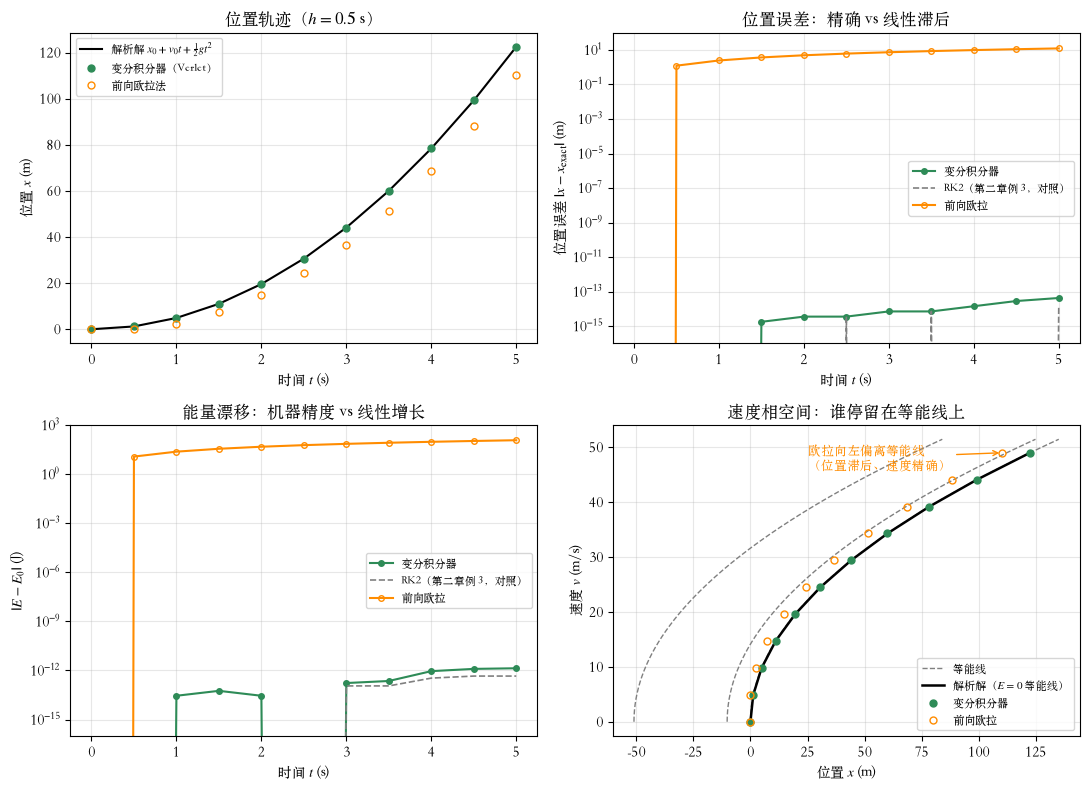

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(11, 8))

# (a) 位置轨迹：解析 vs 变分积分器 vs 欧拉
ax = axs[0, 0]
ax.plot(t, x_exact, '-', color='black', lw=1.5, label='解析解 $x_0 + v_0 t + \\frac{1}{2}gt^2$')
ax.plot(t, x_vi, 'o', color='seagreen', ms=5, label='变分积分器（Verlet）')
ax.plot(t, x_eu, 'o', color='darkorange', ms=5, mfc='none', label='前向欧拉法')
ax.set_xlabel('时间 $t$ (s)')
ax.set_ylabel('位置 $x$ (m)')
ax.set_title('位置轨迹（$h = 0.5$ s）')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# (b) 位置误差（对数纵轴）
ax = axs[0, 1]
ax.semilogy(t, np.abs(x_vi - x_exact) + 1e-300, 'o-', color='seagreen', ms=4, label='变分积分器')
ax.semilogy(t, np.abs(x_rk - x_exact) + 1e-300, '--', color='gray', lw=1.2, label='RK2（第二章例 3，对照）')
ax.semilogy(t, np.abs(x_eu - x_exact), 'o-', color='darkorange', ms=4, mfc='none', label='前向欧拉')
ax.set_xlabel('时间 $t$ (s)')
ax.set_ylabel('位置误差 $|x - x_{\\rm exact}|$ (m)')
ax.set_title('位置误差：精确 vs 线性滞后')
ax.set_ylim(1e-16, 1e2)
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which='both')

# (c) 能量（对数纵轴）
ax = axs[1, 0]
ax.semilogy(t, np.abs(E_vi) + 1e-300, 'o-', color='seagreen', ms=4, label='变分积分器')
ax.semilogy(t, np.abs(E_rk) + 1e-300, '--', color='gray', lw=1.2, label='RK2（第二章例 3，对照）')
ax.semilogy(t, np.abs(E_eu), 'o-', color='darkorange', ms=4, mfc='none', label='前向欧拉')
ax.set_xlabel('时间 $t$ (s)')
ax.set_ylabel('$|E - E_0|$ (J)')
ax.set_title('能量漂移：机器精度 vs 线性增长')
ax.set_ylim(1e-16, 1e3)
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which='both')

# (d) 速度相空间 (x, v)：等能线为 x = v^2/(2g) - E/(mg) 的抛物线
ax = axs[1, 1]
v_line = np.linspace(0, v_exact[-1] * 1.05, 200)
for E_lv in (0.0, 100.0, 500.0):
    ax.plot(v_line**2 / (2 * g) - E_lv / (m * g), v_line, '--', color='gray', lw=1.0,
            label='等能线' if E_lv == 0.0 else None)
ax.plot(x_exact, v_exact, '-', color='black', lw=1.8, label='解析解（$E = 0$ 等能线）')
ax.plot(x_vi, v_vi, 'o', color='seagreen', ms=5, label='变分积分器')
ax.plot(x_eu, v_eu, 'o', color='darkorange', ms=5, mfc='none', label='前向欧拉')
ax.annotate('欧拉向左偏离等能线\n（位置滞后、速度精确）', xy=(x_eu[-1], v_eu[-1]),
            xytext=(x_eu[-1] - 85, v_eu[-1] - 3), fontsize=9, color='darkorange',
            arrowprops=dict(arrowstyle='->', color='darkorange'))
ax.set_xlabel('位置 $x$ (m)')
ax.set_ylabel('速度 $v$ (m/s)')
ax.set_title('速度相空间：谁停留在等能线上')
ax.legend(fontsize=8, loc='lower right')
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig('outputs/1_free_fall_variational.pdf', bbox_inches='tight')   # 矢量图导出
plt.show()

**对照预测 1–2**：

- **位置、动量都精确到机器精度**：变分积分器的位置最大误差 $\sim 10^{-14}$ m、动量（节点速度）$\sim 10^{-14}$ m/s，能量漂移 $\sim 10^{-12}$ J——与 RK2 在数值上不可区分（逐点差 $< 10^{-13}$ m）。原因正如预测 1：解析解是二次多项式，二阶差分**恒等于** $g h^2$，DEL 被逐点精确满足；启动步 $x_1$ 又精确，整条序列自然精确。
- **$-\tfrac{1}{2}mgh$ 是半步的重力冲量**：速度随 $t$ 线性，区间平均速度 $\frac{x_{k+1}-x_k}{h}$ 恰是**中点时刻** $t_{k+1/2}$ 的真实速度；减去 $m\cdot\frac{gh}{2}$（半步冲量）正好折算回节点 $t_k$。速度本质上住在**半节点**上（交错网格），离散 Legendre 变换负责"搬家"。
- **欧拉法的对照**：速度仍精确，位置滞后 $\tfrac{1}{2}ght$（$t = 5$ s 时 $12.25$ m），能量漂移 $120.05$ J——与第二章例 3 的结论一致。
- **一个新现象**：步长减小，变分积分器的误差**反而增大**（$4\times 10^{-14} \to 7\times 10^{-11}$ m）。解析上它对任何 $h$ 都精确——误差全部来自浮点舍入，而步数 $t/h$ 越多、累积越多。机器精度不是零，第二章例 3 的教训在这里重演。

## 追问：变分积分器与欧拉法，差别到底藏在哪里？

预测 3 问了一个刁钻的问题：把三种方法的**位置序列**代回 DEL 差分方程 $x_{k+1} - 2x_k + x_{k-1} - g h^2 = 0$，残差各是多少？再看看三种方法的启动步 $x_1$ 各取了什么值。

**先猜一猜，再运行**：

1. 欧拉法的位置序列满足 DEL 吗？（提示：它的速度是精确的，而二阶差分 $= h(v_k - v_{k-1})$……）
2. 若三种方法都满足同一个差分方程，$12.25$ m 的差距从哪里来？

变分积分器：DEL 残差最大值 = 5.33e-15
RK2：DEL 残差最大值 = 3.38e-14
前向欧拉：DEL 残差最大值 = 2.31e-14

启动步 x_1（精确值 = 1/2 g h^2 = 1.2250 m）：
  变分积分器：x_1 = 1.2250 m（Legendre 变换由 p_0 = m v_0 反解）
  RK2       ：x_1 = 1.2250 m（中点斜率自动补上 1/2 g h^2）
  前向欧拉  ：x_1 = 0.0000 m（只用了左端速度）
  欧拉的启动步若用离散动量解读：p_0 = -2.45 kg·m/s（比真值少了 1/2 mgh = 2.45，恰是半步重力冲量）


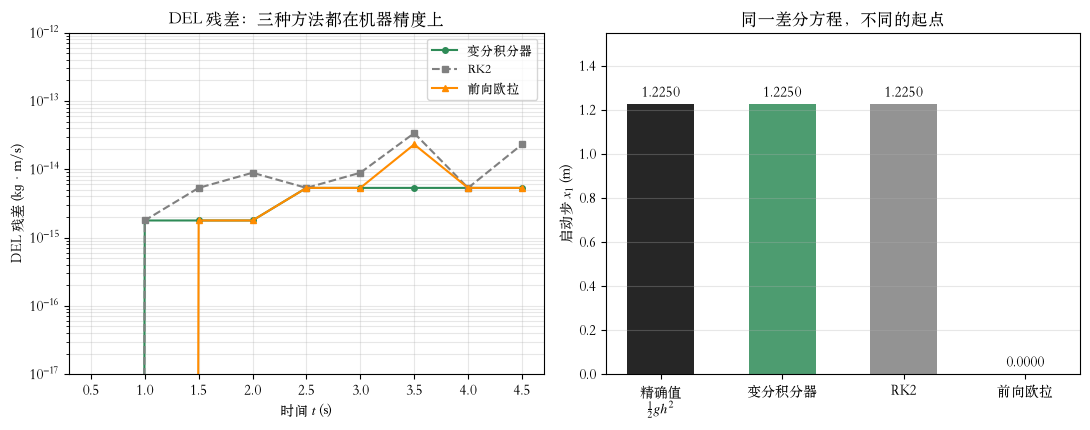

In [4]:
def del_residual(x_seq, h, g, m):
    """DEL 残差：∂2 L_d(x_{k-1}, x_k) + ∂1 L_d(x_k, x_{k+1})，理论值为零"""
    return m * (2 * x_seq[1:-1] - x_seq[:-2] - x_seq[2:]) / h + m * g * h


for name, xs in (('变分积分器', x_vi), ('RK2', x_rk), ('前向欧拉', x_eu)):
    print(f'{name}：DEL 残差最大值 = {np.abs(del_residual(xs, h, g, m)).max():.2e}')

print(f'\n启动步 x_1（精确值 = 1/2 g h^2 = {0.5 * g * h**2:.4f} m）：')
print(f'  变分积分器：x_1 = {x_vi[1]:.4f} m（Legendre 变换由 p_0 = m v_0 反解）')
print(f'  RK2       ：x_1 = {x_rk[1]:.4f} m（中点斜率自动补上 1/2 g h^2）')
print(f'  前向欧拉  ：x_1 = {x_eu[1]:.4f} m（只用了左端速度）')
p0_eff_eu = m * (x_eu[1] - x_eu[0]) / h - 0.5 * m * g * h
print(f'  欧拉的启动步若用离散动量解读：p_0 = {p0_eff_eu:.2f} kg·m/s（比真值少了 1/2 mgh = {0.5 * m * g * h:.2f}，恰是半步重力冲量）')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))

# (a) DEL 残差：三种方法都精确满足
ax1.semilogy(t[1:-1], np.abs(del_residual(x_vi, h, g, m)) + 1e-300, 'o-', color='seagreen', ms=4, label='变分积分器')
ax1.semilogy(t[1:-1], np.abs(del_residual(x_rk, h, g, m)) + 1e-300, 's--', color='gray', ms=4, label='RK2')
ax1.semilogy(t[1:-1], np.abs(del_residual(x_eu, h, g, m)) + 1e-300, '^-', color='darkorange', ms=5, label='前向欧拉')
ax1.set_xlabel('时间 $t$ (s)')
ax1.set_ylabel('DEL 残差 (kg·m/s)')
ax1.set_title('DEL 残差：三种方法都在机器精度上')
ax1.set_ylim(1e-17, 1e-12)
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3, which='both')

# (b) 启动步 x_1 对比
names = ['精确值\n$\\frac{1}{2}gh^2$', '变分积分器', 'RK2', '前向欧拉']
vals = [0.5 * g * h**2, x_vi[1], x_rk[1], x_eu[1]]
colors = ['black', 'seagreen', 'gray', 'darkorange']
bars = ax2.bar(names, vals, color=colors, width=0.55, alpha=0.85)
for bar, v in zip(bars, vals):
    ax2.text(bar.get_x() + bar.get_width() / 2, v + 0.03, f'{v:.4f}', ha='center', fontsize=10)
ax2.set_ylabel('启动步 $x_1$ (m)')
ax2.set_title('同一差分方程，不同的起点')
ax2.set_ylim(0, 1.55)
ax2.grid(alpha=0.3, axis='y')

plt.tight_layout()
fig.savefig('outputs/1_free_fall_variational_del.pdf', bbox_inches='tight')   # 矢量图导出
plt.show()

## 为什么：方程相同，起点不同

- **DEL 不是分水岭**。三种方法的位置序列都精确满足 DEL（残差 $\sim 10^{-14}$，机器精度）——这不奇怪：欧拉法的速度精确，位置的二阶差分 $= h(v_k - v_{k-1}) = gh^2$ 恰好也是 DEL。**差分方程是同一个，差别全在启动步 $x_1$**：变分积分器与 RK2 都给出 $1.225$ m（$= \tfrac{1}{2}gh^2$），欧拉给出 $0$。
- **启动误差如何长成线性漂移**。DEL 的齐次解是 $A + Bk$（常数 + 线性模式）：启动差 $\delta x_1 = -\tfrac{1}{2}gh^2$ 激发 $B$ 模式，误差按 $-\tfrac{1}{2}gh\,t$ 线性增长——这正是左下图欧拉那条误差直线（斜率 $-\tfrac{1}{2}gh = -2.45$ m/s）。差之毫厘（半步重力冲量 $\tfrac{1}{2}mgh$），谬以千里（$t = 5$ s 时差 $12.25$ m）。
- **变分原理的完整性**。离散变分原理同时提供了**方程**（DEL）与**边界条件**（离散 Legendre 变换把 $p_0 = mv_0$ 翻译成 $x_1$）——两件套缺一不可。欧拉法"方程对了、起点错了"；RK2 靠中点斜率**碰巧**补上 $\tfrac{1}{2}gh^2$（常力的特例，见第二章例 5 单摆的结局）；变分积分器则**结构性地**给对。
- **一行代数看穿"精确"（$\alpha$ 家族）**：把单步格式的位置更新推广为 $x_{n+1} = x_n + h\left[\alpha\, v_n + (1-\alpha)\, v_{n+1}\right]$（速度更新 $v_{n+1} = v_n + gh$ 不变），则每步能量增量恒等于

  $$
  \Delta E = \tfrac{1}{2}\left(v_{n+1}^2 - v_n^2\right) - g\left(x_{n+1}-x_n\right) = \left(\alpha - \tfrac{1}{2}\right) g^2 h^2
  $$

  欧拉（$\alpha = 1$）每步恰好多出 $\tfrac{1}{2}g^2h^2$，累计 $\tfrac{1}{2}g^2 h\,t$——第二章例 3 的欧拉漂移从此逐位可预言；RK2（$\alpha = \tfrac{1}{2}$）与本例的变分积分器（启动步精确后等价）恒为零；"反欧拉"（$\alpha = 0$）每步泄漏。**恒等守恒的充要条件，就是位置更新恰用两端速度的中点**——与"启动步差 $\tfrac{1}{2}gh^2$"是同一枚硬币：那半个 $\tfrac{1}{2}gh^2$ 就是全部差别。
- **每步成本**：DEL 递推每步只需**一次**"力"的计算（对一般系统），二阶精度、带动量映射，能量的长期行为也有硬保证（后面各例逐一兑现）——比 RK2 的两次右端更划算。这些几何性质在自由落体里看不出优势（等能线是不闭合的抛物线），等能线闭合的简谐振子才是第一块试金石。

## 长时间模拟：三种漂移，三种命运

把时间拉长四个数量级到 $t = 5\times 10^4$ s（步长仍 $h = 0.5$ s，$10^5$ 步），与第二章例 3 的长时间实验完全同规格。

**先预测，再运行**：

1. 变分积分器的能量漂移会像 RK2 一样由舍入主导吗？增长快慢呢？（提示：DEL 递推 $x_{k+1} = 2x_k - x_{k-1} + gh^2$ 里有两个大数相减……）
2. 三种方法的漂移在 $t = 5\times 10^4$ s 时各到什么量级？

   t (s)         变分积分器 (J)       RK2 (J)        前向欧拉 (J)
       5         1.364e-12    -4.547e-13       1.200e+02
      50         8.586e-09    -3.638e-10       1.200e+03
     500        -1.152e-04    -1.229e-07       1.200e+04
    5000         9.895e-01     3.195e-04       1.201e+05
   50000         6.545e+03     3.631e-01       1.201e+06


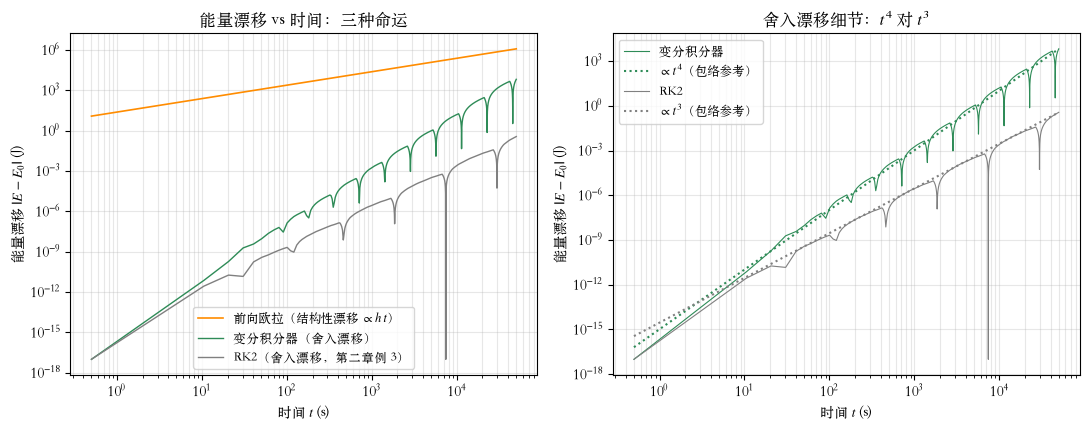

In [5]:
t_long = 5.0e4                      # 总时间 (s)
n_long = int(t_long / h)            # 1e5 步

t_L, xL_vi, vL_vi = variational_free_fall(x0, v0, g, h, n_long)
_, xL_eu, vL_eu = forward_euler_free_fall(x0, v0, g, h, n_long)
_, xL_rk, vL_rk = rk2_midpoint_free_fall(x0, v0, g, h, n_long)

d_vi = 0.5 * m * vL_vi**2 - m * g * xL_vi
d_eu = 0.5 * m * vL_eu**2 - m * g * xL_eu
d_rk = 0.5 * m * vL_rk**2 - m * g * xL_rk

print(f'{"t (s)":>8}{"变分积分器 (J)":>18}{"RK2 (J)":>14}{"前向欧拉 (J)":>16}')
for t_show in (5, 50, 500, 5000, 50000):
    k = int(t_show / h)
    print(f'{t_show:>8.0f}{d_vi[k]:>18.3e}{d_rk[k]:>14.3e}{d_eu[k]:>16.3e}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
idx = slice(1, None, 20)            # 抽稀作图（1e5 个点太密）

# (a) 三方法同台
ax1.loglog(t_L[idx], np.abs(d_eu[idx]), lw=1.2, color='darkorange',
           label='前向欧拉（结构性漂移 $\\propto h\\,t$）')
ax1.loglog(t_L[idx], np.maximum(np.abs(d_vi[idx]), 1e-17), lw=1.0, color='seagreen',
           label='变分积分器（舍入漂移）')
ax1.loglog(t_L[idx], np.maximum(np.abs(d_rk[idx]), 1e-17), lw=1.0, color='gray',
           label='RK2（舍入漂移，第二章例 3）')
ax1.set_xlabel('时间 $t$ (s)')
ax1.set_ylabel('能量漂移 $|E - E_0|$ (J)')
ax1.set_title('能量漂移 vs 时间：三种命运')
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3, which='both')

# (b) 舍入漂移细节：变分积分器 ~ t^4，RK2 ~ t^3
ax2.loglog(t_L[idx], np.maximum(np.abs(d_vi[idx]), 1e-17), '-', lw=0.8, color='seagreen',
           label='变分积分器')
ax2.loglog(t_L[idx], 6.5e-13 * (t_L[idx] / 5.0)**4, ':', color='seagreen', lw=1.5,
           label='$\\propto t^4$（包络参考）')
ax2.loglog(t_L[idx], np.maximum(np.abs(d_rk[idx]), 1e-17), '-', lw=0.8, color='gray',
           label='RK2')
ax2.loglog(t_L[idx], 3.6e-13 * (t_L[idx] / 5.0)**3, ':', color='gray', lw=1.5,
           label='$\\propto t^3$（包络参考）')
ax2.set_xlabel('时间 $t$ (s)')
ax2.set_ylabel('能量漂移 $|E - E_0|$ (J)')
ax2.set_title('舍入漂移细节：$t^4$ 对 $t^3$')
ax2.legend(fontsize=9, loc='upper left')
ax2.grid(alpha=0.3, which='both')

plt.tight_layout()
fig.savefig('outputs/1_free_fall_variational_long.pdf', bbox_inches='tight')   # 矢量图导出
plt.show()

**读图**：

- **三种漂移，三个数量级**（$t = 5\times 10^4$ s 末）：欧拉 $1.2\times 10^6$ J（结构性，$\propto h\,t$）≫ 变分积分器 $6.5\times 10^3$ J > RK2 $0.36$ J。后两者都是浮点舍入的"随机游走"（带符号、上下抖动），但变分积分器**增长更快**：包络约 $\propto t^4$，RK2 约 $\propto t^3$。
- **为什么更快**：DEL 递推 $x_{k+1} = 2x_k - x_{k-1} + gh^2$ 中两个大数相减，每步丢掉约 $\varepsilon_{\rm mach}\cdot x$ 位有效数字，且齐次解的线性模式 $Bk$ 会逐步放大舍入扰动；RK2 的增量式更新没有这一层放大。**两步格式在浮点里更吃亏**——这是精确算法的浮点代价（思考②让你验证改写成一阶"速度形式"能否缓解）。
- **换个角度看绝对值**：变分积分器末位置误差 $137$ m 听着吓人，但末位置本身是 $1.2\times 10^{10}$ m——相对误差仅 $10^{-8}$。物理上，真正的分水岭不在自由落体（等能线不闭合，谈不上"守恒"），而在等能线闭合的系统（例如简谐振子）：那里变分积分器把 RK2 的无界漂移变成了**严格守恒**——能量被恒等地钉在等能线上。至于本例的 $t^4$ 舍入灾难——真的躲不掉吗？下一节把"数"也安排好试试。

## 追问：把数也安排好——"友好步长"驯服 $t^4$ 灾难

上一节看到：DEL 两步递推 $x_{k+1} = 2x_k - x_{k-1} + gh^2$ 里两个大数相减，舍入被按 $t^4$ 放大。但放大要吃"燃料"——**数的表示**。更新里的常数是**乘积** $g\cdot h$（动量）与 $g h^2$（DEL 增量）；把它们搬上**二进制网格**，减法就成了精确数相减。

$g$ 一字不动也能做到：$9.8 = 49/5$，取 $h = 5/2^k$ 型步长即可"洗掉"分母里的 5。对照两档：

$$
h = 0.5:\ \ gh^2 = 2.45 = \tfrac{49}{20}\ \text{（含因子 5，不落格——每步污染）}；\qquad
h = 0.625 = \tfrac{5}{8}:\ \ gh^2 = 3.828125 = \tfrac{245}{64}\ \text{（恰为二进制有限小数）}
$$

**先预测，再运行**：

1. 同样的问题、$g$ 保持 9.8、同样的 $t = 5\times10^4$ s，只把 $h$ 从 0.5 改成 0.625，$6.5\times 10^3$ J 的漂移会变成多少？
2. 把**同一个步长**也发给欧拉法：它的能量还会随机游走吗？

标准步长（g = 9.8, h = 0.5）：变分积分器 max|E| = 6.54e+03 J，RK2 max|E| = 3.63e-01 J
友好步长（g 不变，h = 0.625 = 5/8）：
  变分积分器 max|E| = 1.53e-05 J；位置逐位精确（x_k == 1.9140625 k²）：True
    速度偏差 max|v - 6.125k| = 8.5e-14（动量公式的 ulp 级舍入）
  欧拉 max|E| = 1.50e+06 J；状态同样逐位精确（x_k == 1.9140625 k(k-1)）：True
    欧拉末值 E = 1.500625e+06 J vs 恒等式 1/2 g²ht = 1.500625e+06 J


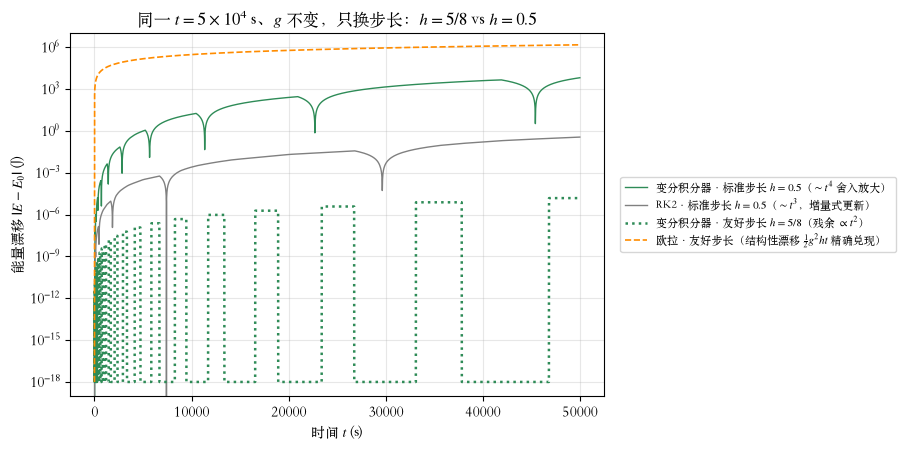

In [6]:
# 友好步长：g 保持 9.8 不变，h = 0.625 = 5/8（DEL 增量 g·h² = 3.828125 = 245/64 恰为二进制有限小数）
h_hs = 0.625
n_hs = int(5.0e4 / h_hs)
_, xH, vH = variational_free_fall(0.0, 0.0, g, h_hs, n_hs)
E_H = 0.5 * vH**2 - g * xH
_, xE, vE = forward_euler_free_fall(0.0, 0.0, g, h_hs, n_hs)
E_E = 0.5 * vE**2 - g * xE

print(f'标准步长（g = 9.8, h = 0.5）：变分积分器 max|E| = {np.max(np.abs(d_vi)):.2e} J，RK2 max|E| = {np.max(np.abs(d_rk)):.2e} J')
print(f'友好步长（g 不变，h = 0.625 = 5/8）：')
print(f'  变分积分器 max|E| = {np.max(np.abs(E_H)):.2e} J；位置逐位精确（x_k == 1.9140625 k²）：'
      f'{all(xH[k] == 1.9140625 * k * k for k in range(0, n_hs + 1, 757))}')
print(f'    速度偏差 max|v - 6.125k| = {np.max(np.abs(vH - 6.125 * np.arange(n_hs + 1))):.1e}（动量公式的 ulp 级舍入）')
print(f'  欧拉 max|E| = {np.max(np.abs(E_E)):.2e} J；状态同样逐位精确（x_k == 1.9140625 k(k-1)）：'
      f'{all(xE[k] == 1.9140625 * k * (k - 1) for k in range(0, n_hs + 1, 757))}')
print(f'    欧拉末值 E = {E_E[-1]:.6e} J vs 恒等式 1/2 g²ht = {0.5 * g**2 * h_hs * 5.0e4:.6e} J')

fig, ax = plt.subplots(figsize=(9.2, 4.6))
ax.semilogy(t_L[idx], np.abs(d_vi[idx]), lw=1.0, color='seagreen',
            label='变分积分器·标准步长 $h=0.5$（$\\sim t^4$ 舍入放大）')
ax.semilogy(t_L[idx], np.abs(d_rk[idx]), lw=1.0, color='gray',
            label='RK2·标准步长 $h=0.5$（$\\sim t^3$，增量式更新）')
ax.semilogy(np.arange(n_hs + 1)[::10] * h_hs, np.maximum(np.abs(E_H[::10]), 1e-18),
            ':', lw=1.8, color='seagreen',
            label='变分积分器·友好步长 $h=5/8$（残余 $\\propto t^2$）')
ax.semilogy(np.arange(n_hs + 1)[::10] * h_hs, np.maximum(np.abs(E_E[::10]), 1e-18),
            '--', lw=1.2, color='darkorange',
            label='欧拉·友好步长（结构性漂移 $\\frac{1}{2} g^2 h t$ 精确兑现）')
ax.set_ylim(1e-19, 1e7)
ax.set_xlabel('时间 $t$ (s)')
ax.set_ylabel('能量漂移 $|E - E_0|$ (J)')
ax.set_title('同一 $t = 5\\times10^4$ s、$g$ 不变，只换步长：$h = 5/8$ vs $h = 0.5$')
ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.02, 0.5))
ax.grid(alpha=0.3, which='both')

plt.tight_layout()
fig.savefig('outputs/1_free_fall_variational_friendly.pdf', bbox_inches='tight')   # 矢量图导出
plt.show()

**读图**：

- **$6.5\times 10^3$ J 掉到 $1.5\times10^{-5}$ J**：$g$ 一字未动，只把 $h$ 换成 $0.625 = 5/8$——DEL 增量 $g h^2 = 3.828125 = 245/64$ 恰为二进制有限小数，两步递推的位置**逐位精确**（$x_k = 1.9140625\,k^2$），速度在 ulp 级（动量公式的舍入路径），漂移直落近九个数量级。上一节的 $t^4$ 放大吃的是"表示"的燃料——$2x_k - x_{k-1}$ 在操作数精确时是**精确相消**，灾难性抵消只在操作数已被污染时才灾难。
- **判据是乘积，不是 $h$ 本身**：$h = 0.5$ 是 2 的幂却不行（$g h = 4.9 = 49/10$ 含因子 5）；$h = 5/8$ 看着不友好却行。**欧拉同享这一个步长**：状态同样逐位精确，能量严格沿 $\tfrac12 g^2 h t$ 爬到 $1.5\times10^6$ J——**算法决定该不该漂，数的表示决定漂得准不准**。
- **残余 $\propto t^2$ 与特权条款**：轨迹积分的其实是精确有理数 $49/5 = 9.8$，而能量读数里的 $\mathrm{fl}(9.8) \ne 9.8$（差 $\varepsilon_0 \approx 1.3\times10^{-15}$）留下 $|E| \approx \varepsilon_0 |x| \propto t^2$ 的尾巴；要归零得连 $g$ 的存储值也搬上网格。$9.8 = 49/5$ 的有限小数身份 + $x_0 = 0$ 落格是这一切的特权——一般系统没有这种网格。思考②的"速度形式改写"是同一课的另一面：**算法的代数不变，变的是数的命运**。

## 结论与思考

**先对照引言的三个预测**（DEL 是否被精确满足？半步冲量折算到哪？欧拉的位置序列满足 DEL 吗？），再记住几条：

- **离散变分原理 = 方程 + 边界条件**：DEL 给出差分方程，离散 Legendre 变换把初始动量翻译成正确的启动步。欧拉法方程也对、却输在起点——差之 $\tfrac{1}{2}gh^2$，谬以 $\tfrac{1}{2}gh\,t$。
- **"精确"的两种来源**：RK2 靠常力下"中点斜率 = 平均斜率"的巧合（换成单摆就失效，第二章例 5）；变分积分器靠"二次解的二阶差分恒为 $gh^2$"与结构性的 Legendre 启动。前者是特权，后者是原理。
- **几何性质免费附送**：变分积分器自动保动量映射，能量在长时间里也有硬保证（后面各例逐一兑现）——每步只需一次右端计算。这些性质的价值在自由落体里还看不出来——等能线是开口的抛物线，没有"有界"可言。
- **浮点世界里没有严格守恒**：变分积分器解析上对任何 $h$ 精确，浮点里舍入照样累积，而且两步递推的放大让它比 RK2 涨得更快（$t^4$ 对 $t^3$）——但选对步长（$h = 5/8$，让 $g h^2$ 落上二进制网格）能把漂移再压近九个数量级（上一节）。

**思考**：

1. 把本例的变分积分器搬到**简谐振子**（$L = \tfrac{1}{2}m\dot x^2 - \tfrac{1}{2}kx^2$）与**大振幅单摆**：位置不再精确，能量还会像 RK2 那样无界漂移吗？（这正是本章的主线。）
2. 把两步递推改写成等价的一阶"速度形式"（velocity Verlet：$v_{k+1/2} = v_{k-1/2} + gh$，$x_{k+1} = x_k + h v_{k+1/2}$）重跑长时间模拟：舍入漂移还是 $\propto t^4$ 吗？
3. 欧拉法的位置序列也精确满足 DEL——它算不算一个变分积分器？差在哪个环节？
